In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import torch
import torch.nn as nn
from torchvision import models, transforms
import numpy as np
import random

import os
CKPT_DIR = "checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)

#Load Data

In [3]:
from torchvision.datasets import OxfordIIITPet
from torch.utils.data import ConcatDataset

trainval_dataset = OxfordIIITPet("data", split="trainval", download=True)
test_dataset = OxfordIIITPet("data", split="test", download=True)

100%|██████████| 792M/792M [00:23<00:00, 34.2MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 14.8MB/s]


In [4]:
trainval_dataset.classes

['Abyssinian',
 'American Bulldog',
 'American Pit Bull Terrier',
 'Basset Hound',
 'Beagle',
 'Bengal',
 'Birman',
 'Bombay',
 'Boxer',
 'British Shorthair',
 'Chihuahua',
 'Egyptian Mau',
 'English Cocker Spaniel',
 'English Setter',
 'German Shorthaired',
 'Great Pyrenees',
 'Havanese',
 'Japanese Chin',
 'Keeshond',
 'Leonberger',
 'Maine Coon',
 'Miniature Pinscher',
 'Newfoundland',
 'Persian',
 'Pomeranian',
 'Pug',
 'Ragdoll',
 'Russian Blue',
 'Saint Bernard',
 'Samoyed',
 'Scottish Terrier',
 'Shiba Inu',
 'Siamese',
 'Sphynx',
 'Staffordshire Bull Terrier',
 'Wheaten Terrier',
 'Yorkshire Terrier']

#Memilih 10 ras

In [5]:
from torch.utils.data import Subset
selected_name = [
    "Abyssinian", "Bengal", "Birman", "Bombay", "Persian",
    "Beagle", "Boxer", "Chihuahua", "Pug", "Samoyed"
]

full_label = np.concatenate([
    np.asarray(trainval_dataset._labels),
    np.asarray(test_dataset._labels)
])

selected_idx = [trainval_dataset.classes.index(name)for name in selected_name]

filtered_indices = np.where(np.isin(full_label, selected_idx))[0]
filtered_indices

array([   0,    1,    2, ..., 6658, 6659, 6660])

In [6]:
len(filtered_indices)

1981

In [7]:
remap = {name: i for i, name in enumerate(selected_idx)}
y = np.array([remap[i] for i in full_label[filtered_indices]])
len(y)

1981

In [8]:
np.unique(y)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])

#Split training, validation, testing dataset

In [9]:
SEED = 42
BATCH_SIZE = 32

In [10]:
from sklearn.model_selection import train_test_split

x_train, x_tmp, y_train, y_tmp = train_test_split( filtered_indices, y, test_size=0.3, random_state=SEED, stratify=y )
x_val, x_test, y_val, y_test = train_test_split(x_tmp, y_tmp, test_size=0.5, random_state=SEED, stratify=y_tmp)

#B1

In [11]:
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=None)
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)
model = model.to(device)

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

https://www.geeksforgeeks.org/deep-learning/how-do-you-use-pytorchs-dataset-and-dataloader-classes-for-custom-data/

In [12]:
from torch.utils.data import Dataset, DataLoader
class PetSubset(Dataset):
    def __init__(self, full_dataset, indices, labels, transform):
        self.full_dataset = full_dataset
        self.indices = indices
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        image, _ = self.full_dataset[int(self.indices[idx])]
        image = self.transform(image)
        label = int(self.labels[idx])
        return image, label

In [13]:
full_dataset = ConcatDataset([trainval_dataset, test_dataset])

In [14]:
eval_transforms = weights.transforms()
train_subset = PetSubset(full_dataset, x_train, y_train, eval_transforms)
val_subset = PetSubset( full_dataset, x_val, y_val, eval_transforms)
test_subset = PetSubset(full_dataset, x_test, y_test, eval_transforms)

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

In [15]:
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable Parametes: ", trainable_params)

Trainable Parametes:  11181642


In [16]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

In [17]:
lr =[]

for i in optimizer.param_groups:
    print(f"Learning Rate = {i['lr']}")
    lr.append(i['lr'])

Learning Rate = 0.001


In [18]:
def run_epoch_train(data_load):
    model.train()
    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in data_load:
        images = images.to(device)
        labels = labels.to(device)

        output = model(images)
        loss = criterion(output, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        size = labels.size(0)
        train_loss_sum += loss.item() * size
        train_correct += (output.argmax(dim=1) == labels).sum().item()
        train_total += size

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    return train_loss, train_acc

def run_epoch_val(data_load):
    model.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in data_load:
              images = images.to(device)
              labels = labels.to(device)

              output = model(images)
              loss = criterion(output, labels)

              size = labels.size(0)
              val_loss_sum += loss.item() * size
              val_correct += (output.argmax(dim=1) == labels).sum().item()
              val_total += size

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    return val_loss, val_acc

In [19]:
import time
from sklearn.metrics import f1_score

import time, json, torch, pandas as pd
from sklearn.metrics import f1_score

ALL_HISTORY, ALL_RESULTS = [], []

def save_logs():
    pd.DataFrame(ALL_HISTORY).to_csv("log_per_epoch.csv", index=False)
    pd.DataFrame(ALL_RESULTS).to_csv("log_ringkasan.csv", index=False)
    meta = dict(seed=SEED, batch_size=BATCH_SIZE, torch=torch.__version__, device=str(device),
                gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu")
    with open("log_hasil.json", "w") as f:
        json.dump(dict(meta=meta, per_epoch=ALL_HISTORY, ringkasan=ALL_RESULTS), f, indent=2, default=str)

def fit(model, optimizer, name, trainable_params, lr):
    PATIENCE = 3
    best_loss, wait, best_epoch = float("inf"), 0, 0
    best_val_acc, best_train_acc = 0, 0
    start = time.time()

    for epoch in range(1, 50):
        train_loss, train_acc = run_epoch_train(train_loader)
        val_loss, val_acc = run_epoch_val(val_loader)
        print(f"epoch {epoch} | train loss {train_loss:.3f} acc {train_acc:.3f} | val loss {val_loss:.3f} acc {val_acc:.3f}")

        # Early stopping
        if val_loss < best_loss:
            best_loss, best_epoch, wait = val_loss, epoch, 0
            best_val_acc, best_train_acc = val_acc, train_acc
            torch.save(model.state_dict(), f"{CKPT_DIR}/{name}.pt")
        else:
            wait += 1
            if wait >= PATIENCE:
                print("Early stopping")
                break

    duration = time.time() - start

    print("best epoch: ", best_epoch)
    print("best validation loss: ", best_loss)
    print("durasi: ", duration)

    model.load_state_dict(torch.load(f"{CKPT_DIR}/{name}.pt"))
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            out = model(images.to(device))
            preds += out.argmax(1).cpu().tolist()
            trues += labels.tolist()

    f1 = f1_score(trues, preds, average="macro")
    print("f1: ", f1)

    for h in ALL_HISTORY:
        if h["kondisi"] == name:
            h["best_epoch"] = (h["epoch"] == best_epoch)

    result = dict(name=name, best_epoch=best_epoch, best_train_acc=best_train_acc,
                  best_val_acc=best_val_acc, gap=best_train_acc - best_val_acc, f1=f1,
                  duration=duration, trainable_params=trainable_params, lr=lr, best_val_loss=best_loss)
    ALL_RESULTS.append(result)
    ALL_HISTORY.append(dict(kondisi=name, epoch=epoch, train_loss=train_loss, train_acc=train_acc,
                                val_loss=val_loss, val_acc=val_acc))
    save_logs()
    return result

In [20]:
result_b1 = fit(model, optimizer, "b1", trainable_params, lr)
print(result_b1)

epoch 1 | train loss 2.146 acc 0.263 | val loss 3.351 acc 0.219
epoch 2 | train loss 1.825 acc 0.368 | val loss 2.676 acc 0.266
epoch 3 | train loss 1.684 acc 0.422 | val loss 1.928 acc 0.333
epoch 4 | train loss 1.570 acc 0.449 | val loss 1.740 acc 0.424
epoch 5 | train loss 1.487 acc 0.483 | val loss 1.597 acc 0.465
epoch 6 | train loss 1.358 acc 0.531 | val loss 1.534 acc 0.492
epoch 7 | train loss 1.270 acc 0.566 | val loss 2.197 acc 0.323
epoch 8 | train loss 1.166 acc 0.602 | val loss 2.259 acc 0.394
epoch 9 | train loss 1.101 acc 0.613 | val loss 1.601 acc 0.488
Early stopping
best epoch:  6
best validation loss:  1.5339913336114852
durasi:  3818.084558725357
f1:  0.4875962181753204
{'name': 'b1', 'best_epoch': 6, 'best_train_acc': 0.5310245310245311, 'best_val_acc': 0.49158249158249157, 'gap': 0.0394420394420395, 'f1': 0.4875962181753204, 'duration': 3818.084558725357, 'trainable_params': 11181642, 'lr': [0.001], 'best_val_loss': 1.5339913336114852}


#B2

In [21]:
torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)
for p in model.parameters():
    p.requires_grad = False

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)
model = model.to(device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 135MB/s]


In [22]:
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable Parametes: ", trainable_params)

Trainable Parametes:  5130


In [23]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

lr =[]

for i in optimizer.param_groups:
    print(f"Learning Rate = {i['lr']}")
    lr.append(i['lr'])

Learning Rate = 0.001


In [24]:
result_b2 = fit(model, optimizer, "b2", trainable_params, lr)
print(result_b2)

epoch 1 | train loss 1.204 acc 0.704 | val loss 0.496 acc 0.943
epoch 2 | train loss 0.383 acc 0.949 | val loss 0.271 acc 0.949
epoch 3 | train loss 0.250 acc 0.959 | val loss 0.219 acc 0.943
epoch 4 | train loss 0.198 acc 0.973 | val loss 0.171 acc 0.963
epoch 5 | train loss 0.164 acc 0.970 | val loss 0.150 acc 0.966
epoch 6 | train loss 0.142 acc 0.975 | val loss 0.129 acc 0.976
epoch 7 | train loss 0.121 acc 0.980 | val loss 0.124 acc 0.973
epoch 8 | train loss 0.105 acc 0.983 | val loss 0.122 acc 0.976
epoch 9 | train loss 0.101 acc 0.982 | val loss 0.111 acc 0.970
epoch 10 | train loss 0.094 acc 0.983 | val loss 0.102 acc 0.980
epoch 11 | train loss 0.085 acc 0.981 | val loss 0.097 acc 0.983
epoch 12 | train loss 0.078 acc 0.984 | val loss 0.108 acc 0.966
epoch 13 | train loss 0.070 acc 0.989 | val loss 0.092 acc 0.983
epoch 14 | train loss 0.062 acc 0.991 | val loss 0.087 acc 0.983
epoch 15 | train loss 0.059 acc 0.996 | val loss 0.092 acc 0.976
epoch 16 | train loss 0.057 acc 0.

#B3

In [25]:
torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)

for param in model.parameters():
  param.requires_grad =False

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)

for param in model.layer4.parameters():
  param.requires_grad = True

model = model.to(device)

In [26]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(),     "lr": 1e-3},
], weight_decay=1e-2)

lr =[]

for i in optimizer.param_groups:
    print(f"Learning Rate = {i['lr']}")
    lr.append(i['lr'])

Learning Rate = 0.0001
Learning Rate = 0.001


In [27]:
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable Parametes: ", trainable_params)

Trainable Parametes:  8398858


In [28]:
result_b3= fit(model, optimizer, "b3", trainable_params, lr)
print(result_b3)

epoch 1 | train loss 0.535 acc 0.860 | val loss 0.116 acc 0.976
epoch 2 | train loss 0.053 acc 0.993 | val loss 0.094 acc 0.980
epoch 3 | train loss 0.025 acc 0.996 | val loss 0.130 acc 0.953
epoch 4 | train loss 0.011 acc 1.000 | val loss 0.084 acc 0.980
epoch 5 | train loss 0.007 acc 1.000 | val loss 0.087 acc 0.983
epoch 6 | train loss 0.006 acc 1.000 | val loss 0.089 acc 0.980
epoch 7 | train loss 0.003 acc 1.000 | val loss 0.085 acc 0.980
Early stopping
best epoch:  4
best validation loss:  0.08399470258341092
durasi:  1663.058177947998
f1:  0.9799962952672038
{'name': 'b3', 'best_epoch': 4, 'best_train_acc': 1.0, 'best_val_acc': 0.9797979797979798, 'gap': 0.02020202020202022, 'f1': 0.9799962952672038, 'duration': 1663.058177947998, 'trainable_params': 8398858, 'lr': [0.0001, 0.001], 'best_val_loss': 0.08399470258341092}


#B4

### non augmentasi

In [29]:
torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)

for param in model.parameters():
  param.requires_grad =False

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)

for param in model.layer4.parameters():
  param.requires_grad = True

model = model.to(device)

In [30]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(),     "lr": 1e-3},
], weight_decay=1e-2)

lr =[]

for i in optimizer.param_groups:
    print(f"Learning Rate = {i['lr']}")
    lr.append(i['lr'])

Learning Rate = 0.0001
Learning Rate = 0.001


In [31]:
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean,
                         std=weights.transforms().std),
    ])

In [32]:
eval_transforms = weights.transforms()
train_subset = PetSubset(full_dataset, x_train, y_train, train_transforms)

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

In [33]:
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable Parametes: ", trainable_params)

Trainable Parametes:  8398858


In [34]:
result_b4_nonaug= fit(model, optimizer, "b4_nonaug", trainable_params, lr)
print(result_b4_nonaug)

epoch 1 | train loss 0.549 acc 0.854 | val loss 0.112 acc 0.973
epoch 2 | train loss 0.081 acc 0.983 | val loss 0.101 acc 0.973
epoch 3 | train loss 0.028 acc 0.998 | val loss 0.087 acc 0.976
epoch 4 | train loss 0.015 acc 0.999 | val loss 0.098 acc 0.970
epoch 5 | train loss 0.013 acc 0.999 | val loss 0.091 acc 0.973
epoch 6 | train loss 0.009 acc 0.999 | val loss 0.099 acc 0.970
Early stopping
best epoch:  3
best validation loss:  0.08652994885839999
durasi:  1428.8363811969757
f1:  0.9765319644062608
{'name': 'b4_nonaug', 'best_epoch': 3, 'best_train_acc': 0.9978354978354979, 'best_val_acc': 0.9764309764309764, 'gap': 0.021404521404521426, 'f1': 0.9765319644062608, 'duration': 1428.8363811969757, 'trainable_params': 8398858, 'lr': [0.0001, 0.001], 'best_val_loss': 0.08652994885839999}


### aug

In [35]:
torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

weights = models.ResNet18_Weights.IMAGENET1K_V1
model = models.resnet18(weights=weights)

for param in model.parameters():
  param.requires_grad =False

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, 10)

for param in model.layer4.parameters():
  param.requires_grad = True

model = model.to(device)

In [36]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW([
    {"params": model.layer4.parameters(), "lr": 1e-4},
    {"params": model.fc.parameters(),     "lr": 1e-3},
], weight_decay=1e-2)

lr =[]

for i in optimizer.param_groups:
    print(f"Learning Rate = {i['lr']}")
    lr.append(i['lr'])

Learning Rate = 0.0001
Learning Rate = 0.001


In [37]:
train_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=weights.transforms().mean, std=weights.transforms().std),
    ])

In [38]:
eval_transforms = weights.transforms()
train_subset = PetSubset(full_dataset, x_train, y_train, train_transforms)

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

In [39]:
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable Parametes: ", trainable_params)

Trainable Parametes:  8398858


In [40]:
result_b4_aug= fit(model, optimizer, "b4_aug", trainable_params, lr)
print(result_b4_aug)

epoch 1 | train loss 0.621 acc 0.829 | val loss 0.121 acc 0.976
epoch 2 | train loss 0.130 acc 0.970 | val loss 0.136 acc 0.960
epoch 3 | train loss 0.084 acc 0.981 | val loss 0.127 acc 0.960
epoch 4 | train loss 0.041 acc 0.994 | val loss 0.119 acc 0.960
epoch 5 | train loss 0.040 acc 0.990 | val loss 0.112 acc 0.966
epoch 6 | train loss 0.032 acc 0.994 | val loss 0.101 acc 0.973
epoch 7 | train loss 0.016 acc 0.998 | val loss 0.130 acc 0.963
epoch 8 | train loss 0.022 acc 0.994 | val loss 0.097 acc 0.973
epoch 9 | train loss 0.016 acc 0.997 | val loss 0.101 acc 0.966
epoch 10 | train loss 0.016 acc 0.997 | val loss 0.147 acc 0.946
epoch 11 | train loss 0.024 acc 0.991 | val loss 0.095 acc 0.970
epoch 12 | train loss 0.010 acc 0.999 | val loss 0.093 acc 0.970
epoch 13 | train loss 0.008 acc 0.998 | val loss 0.101 acc 0.973
epoch 14 | train loss 0.005 acc 1.000 | val loss 0.162 acc 0.953
epoch 15 | train loss 0.007 acc 0.998 | val loss 0.153 acc 0.956
Early stopping
best epoch:  12
bes

#B5

In [41]:
torch.manual_seed(SEED)
random.seed(SEED)
np.random.seed(SEED)

train_loader = DataLoader(PetSubset(full_dataset, x_train, y_train, eval_transforms),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

weight = models.EfficientNet_B0_Weights.IMAGENET1K_V1
model = models.efficientnet_b0(weights=weight)

for p in model.parameters():
    p.requires_grad = False
model.classifier[1] = nn.Linear(model.classifier[1].in_features, 10)
for p in model.features[-2:].parameters():
    p.requires_grad = True
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW([
    {"params": model.features[-2:].parameters(), "lr": 1e-4},
    {"params": model.classifier.parameters(),    "lr": 1e-3},
], weight_decay=1e-2)

lr = [g["lr"] for g in optimizer.param_groups]
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())
print("Learning Rate:", lr)
print(f"Trainable: {trainable_params:,} / Total: {total_params:,}")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 92.5MB/s]


Learning Rate: [0.0001, 0.001]
Trainable: 1,142,202 / Total: 4,020,358


In [42]:
result_b5 = fit(model, optimizer, "b5", trainable_params, lr)
result_b5["total_params"] = total_params
print(result_b5)

epoch 1 | train loss 1.107 acc 0.793 | val loss 0.280 acc 0.970
epoch 2 | train loss 0.270 acc 0.950 | val loss 0.163 acc 0.973
epoch 3 | train loss 0.162 acc 0.962 | val loss 0.111 acc 0.980
epoch 4 | train loss 0.118 acc 0.973 | val loss 0.097 acc 0.990
epoch 5 | train loss 0.088 acc 0.982 | val loss 0.088 acc 0.987
epoch 6 | train loss 0.061 acc 0.989 | val loss 0.080 acc 0.983
epoch 7 | train loss 0.050 acc 0.991 | val loss 0.077 acc 0.987
epoch 8 | train loss 0.033 acc 0.994 | val loss 0.071 acc 0.987
epoch 9 | train loss 0.033 acc 0.993 | val loss 0.073 acc 0.990
epoch 10 | train loss 0.026 acc 0.996 | val loss 0.065 acc 0.993
epoch 11 | train loss 0.027 acc 0.994 | val loss 0.069 acc 0.987
epoch 12 | train loss 0.023 acc 0.996 | val loss 0.069 acc 0.983
epoch 13 | train loss 0.021 acc 0.996 | val loss 0.068 acc 0.990
Early stopping
best epoch:  10
best validation loss:  0.06479383722223618
durasi:  2162.3999218940735
f1:  0.9796437545123371
{'name': 'b5', 'best_epoch': 10, 'best

In [43]:
cmp = pd.DataFrame([
    dict(model="B3 ResNet-18", total_params=11181642, **{k: result_b3[k] for k in ("trainable_params","best_epoch","best_val_acc","f1","duration")}),
    dict(model="B5 EfficientNet-B0", **{k: result_b5[k] for k in ("total_params","trainable_params","best_epoch","best_val_acc","f1","duration")}),
])
cmp["detik_per_epoch"] = [result_b3["duration"]/result_b3["best_epoch"] if False else None, None]
display(cmp)

,model,total_params,trainable_params,best_epoch,best_val_acc,f1,duration,detik_per_epoch
0,B3 ResNet-18,11181642,8398858,4,0.979798,0.979996,1663.058178,None
1,B5 EfficientNet-B0,4020358,1142202,10,0.993266,0.979644,2162.399922,None


#Evaluation

In [60]:
import pandas as pd

df_epoch = pd.read_csv("log_per_epoch.csv")
df_sum   = pd.read_csv("log_ringkasan.csv")

n_epoch = df_epoch.groupby("name").size()
df_sum["jumlah_epoch"]    = df_sum["name"].map(n_epoch)
df_sum["detik_per_epoch"] = (df_sum["duration"] / df_sum["jumlah_epoch"]).round(1)

display(df_sum[["name", "trainable_params",  "lr", "jumlah_epoch", "best_epoch",
                "best_val_acc", "best_val_loss", "best_train_acc", "gap", "f1", "duration", "detik_per_epoch"]])

,name,trainable_params,lr,jumlah_epoch,best_epoch,best_val_acc,best_val_loss,best_train_acc,gap,f1,duration,detik_per_epoch
0,b1,11181642,[0.001],9,6,0.491582,1.533991,0.531025,0.039442,0.487596,3818.084559,424.2
1,b2,5130,[0.001],27,24,0.979798,0.078235,0.996392,0.016595,0.963351,4999.989520,185.2
2,b3,8398858,"[0.0001, 0.001]",7,4,0.979798,0.083995,1.000000,0.020202,0.979996,1663.058178,237.6
3,b4_nonaug,8398858,"[0.0001, 0.001]",6,3,0.976431,0.086530,0.997835,0.021405,0.976532,1428.836381,238.1
4,b4_aug,8398858,"[0.0001, 0.001]",15,12,0.969697,0.092879,0.998557,0.028860,0.960194,3722.132586,248.1
5,b5,1142202,"[0.0001, 0.001]",13,10,0.993266,0.064794,0.996392,0.003127,0.979644,2162.399922,166.3


In [53]:
nonaug, aug = result_b4_nonaug, result_b4_aug
print(f"Selisih val acc  B4: {aug['best_val_acc'] - nonaug['best_val_acc']}")
print(f"Selisih Macro F1 B4: {aug['f1'] - nonaug['f1']}")
print(f"Gap  noaug: {nonaug['gap']} aug: {aug['gap']}")
print(f"Epoch konvergen noaug: {nonaug['best_epoch']} aug: {aug['best_epoch']}")

Selisih val acc  B4: -0.006734006734006703
Selisih Macro F1 B4: -0.01633760585047994
Gap  noaug: 0.021404521404521426 aug: 0.028860028860028808
Epoch konvergen noaug: 3 aug: 12


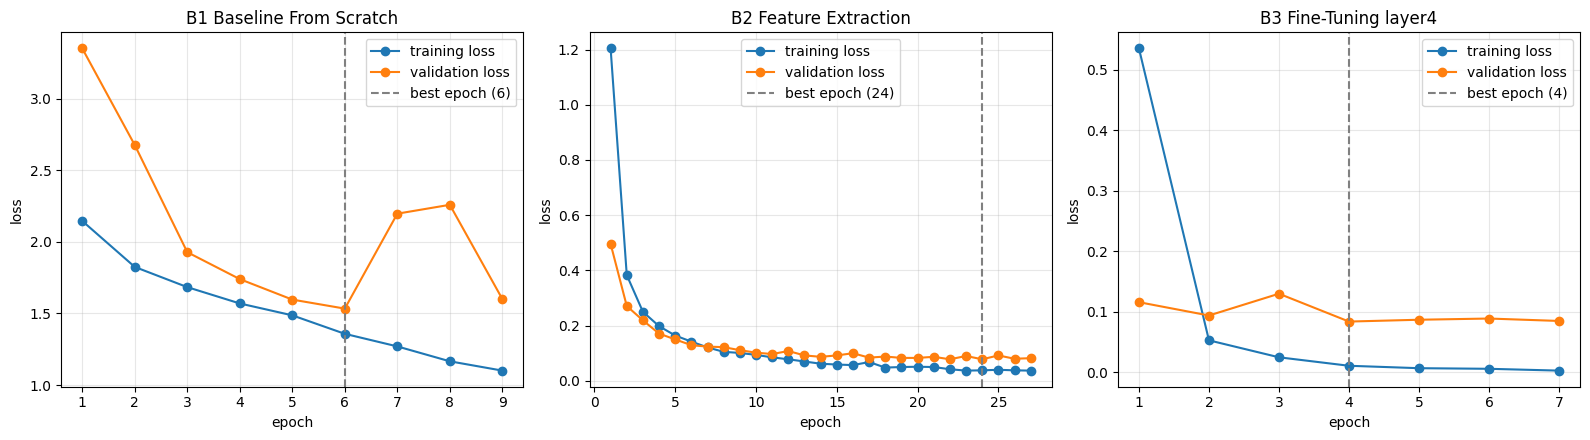

In [66]:
import matplotlib.pyplot as plt, pandas as pd

df_hist = pd.read_csv("log_per_epoch.csv")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, (judul, name) in zip(ax, [("B1 Baseline From Scratch", "b1"),
                                 ("B2 Feature Extraction", "b2"),
                                 ("B3 Fine-Tuning layer4", "b3")]):
    h = df_hist[df_hist.name == name].sort_values("epoch")
    best = int(h.loc[h.best_epoch, "epoch"].iloc[0])
    a.plot(h.epoch, h.train_loss, marker="o", label="training loss")
    a.plot(h.epoch, h.val_loss, marker="o", label="validation loss")
    a.axvline(best, ls="--", c="gray", label=f"best epoch ({best})")
    a.set_title(judul); a.set_xlabel("epoch"); a.set_ylabel("loss")
    a.grid(alpha=0.3); a.legend()
plt.tight_layout(); plt.savefig("kurva_loss.png", dpi=150); plt.show()

salah: 6/298
conf < 0.7: 8


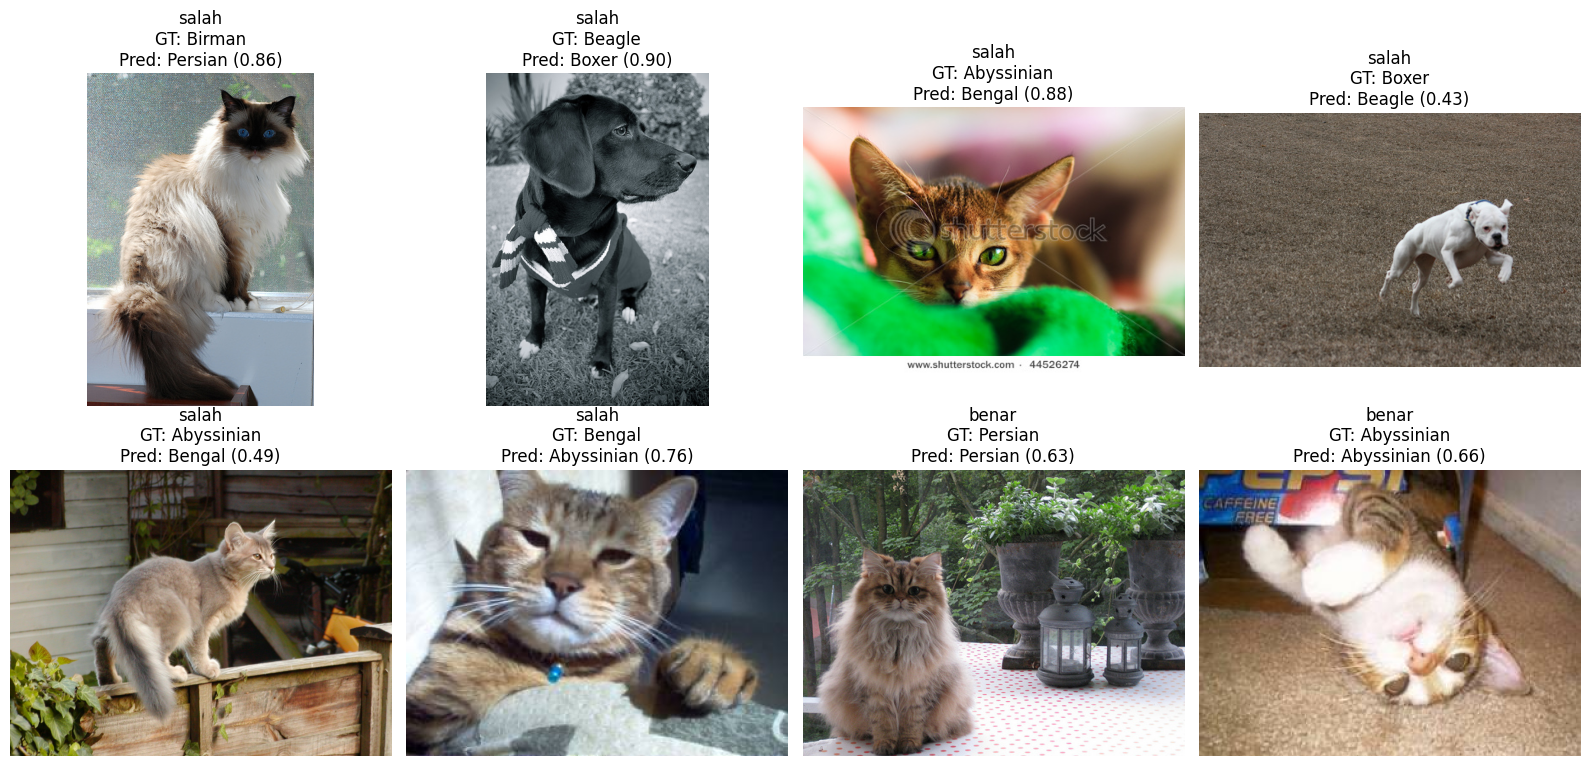

In [56]:
import os, matplotlib.pyplot as plt

chosen = ["Abyssinian","Bengal","Birman","Bombay","Persian","Beagle","Boxer","Chihuahua","Pug","Samoyed"]

def load_model(path):
    m = models.resnet18(weights=None)
    m.fc = nn.Linear(512, 10)
    m.load_state_dict(torch.load(path, map_location=device))
    return m.to(device).eval()

best_model = load_model(f"{CKPT_DIR}/b3.pt")

wrong, low_conf = [], []
with torch.no_grad():
    for i in range(len(test_subset)):
        img, y = test_subset[i]
        p = torch.softmax(best_model(img.unsqueeze(0).to(device)), 1)[0]
        pred = p.argmax().item()
        if pred != y:
            wrong.append((i, y, pred, p[pred].item()))
        elif p[pred].item() < 0.7:
            low_conf.append((i, y, pred, p[pred].item()))
print(f"salah: {len(wrong)}/{len(test_subset)}\nconf < 0.7: {len(low_conf)}")

samples = (wrong + low_conf)[:8]
fig, ax = plt.subplots(2, 4, figsize=(16, 8))
for a in ax.flat:
    a.axis("off")
for a, (i, y, pred, conf) in zip(ax.flat, samples):
    orig, _ = full_dataset[int(x_test[i])]
    a.imshow(orig)

    if y != pred:
        status = "salah"
    else:
        status = "benar"
    a.set_title(f"{status}\nGT: {chosen[y]}\nPred: {chosen[pred]} ({conf:.2f})")
plt.tight_layout()
plt.show()

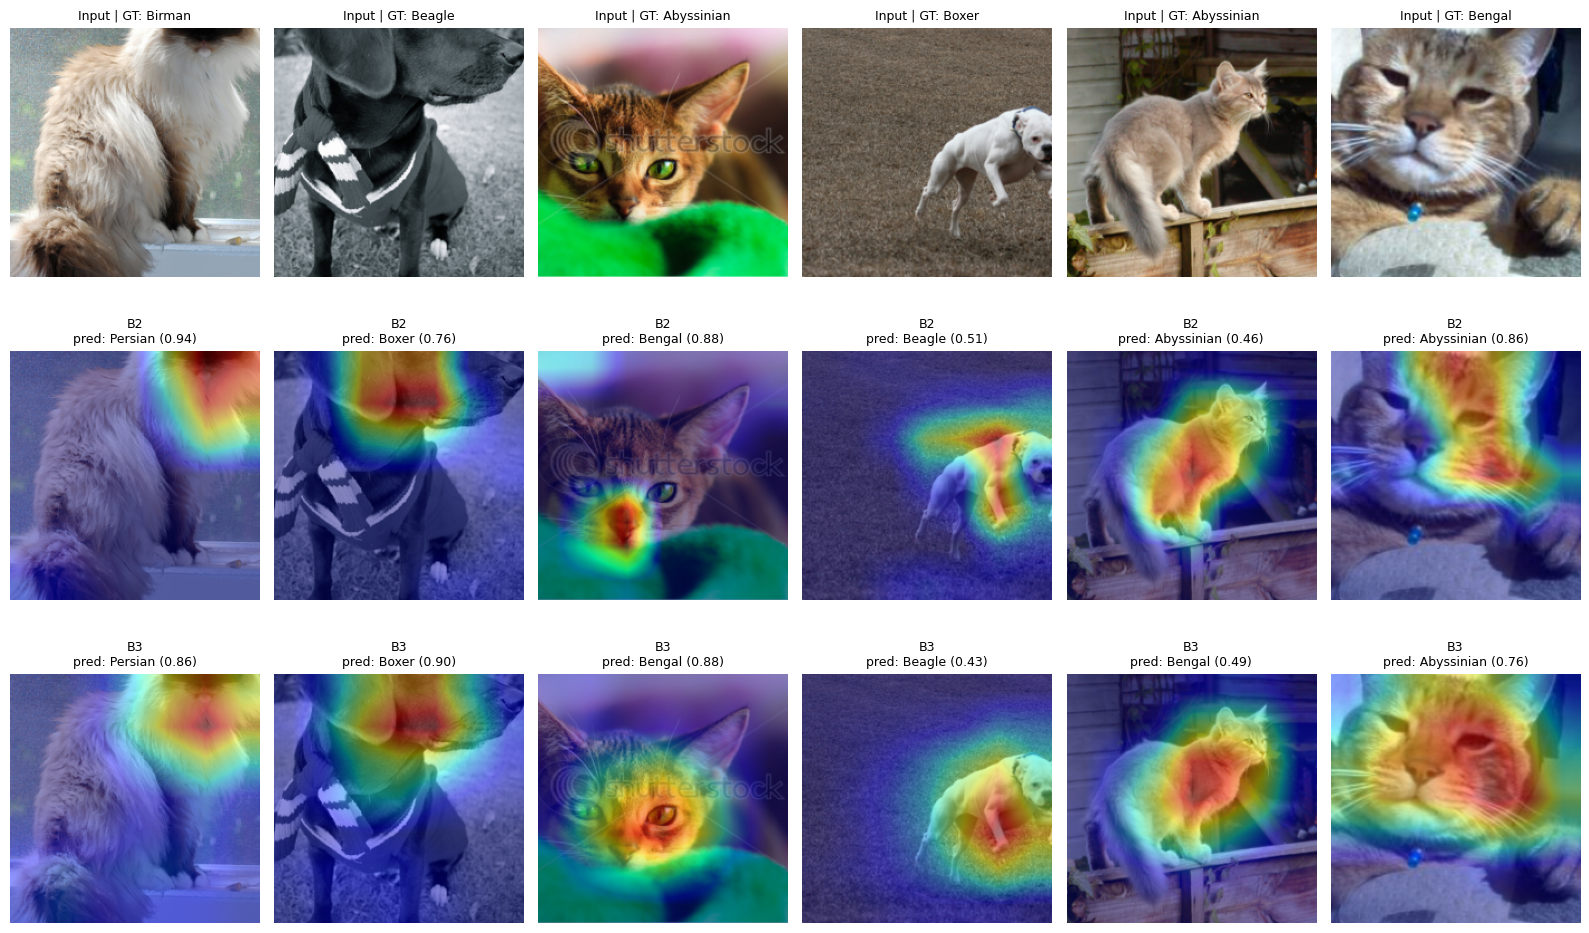

In [68]:
import torch.nn.functional as F
import matplotlib.pyplot as plt

b2 = load_model(f"{CKPT_DIR}/b2.pt")
b3 = load_model(f"{CKPT_DIR}/b3.pt")

def gradcam(m, img, target):
    acts = {}
    def hook(mod, inp, out):
        acts["a"] = out
    h = m.layer4.register_forward_hook(hook)
    x = img.unsqueeze(0).to(device).requires_grad_(True)
    out = m(x)

    h.remove()
    probs = torch.softmax(out, 1)[0]
    grad = torch.autograd.grad(out[0, target], acts["a"])[0]
    w = grad.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * acts["a"]).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=(224, 224), mode="bilinear", align_corners=False)[0, 0].detach().cpu()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam.numpy(), probs.argmax().item(), probs.max().item()

mean_t = torch.tensor(mean).view(3, 1, 1)
std_t = torch.tensor(std).view(3, 1, 1)
idx = [s[0] for s in samples[:6]]

fig, ax = plt.subplots(3, len(idx), figsize=(16, 10))
for j, i in enumerate(idx):
    img, y = test_subset[i]
    show = (img * std_t + mean_t).permute(1, 2, 0).clamp(0, 1).numpy()
    ax[0, j].imshow(show); ax[0, j].set_title(f"Input | GT: {chosen[y]}", fontsize=9)
    for r, (m, nm) in enumerate([(b2, "B2"), (b3, "B3")], start=1):
        cam, p, c = gradcam(m, img, y)
        ax[r, j].imshow(show); ax[r, j].imshow(cam, cmap="jet", alpha=0.45)
        ax[r, j].set_title(f"{nm}\npred: {chosen[p]} ({c:.2f})", fontsize=9)
for a in ax.flat: a.axis("off")
plt.tight_layout()
plt.show()